# Exploratory Data Analysis — Major vs Minor Chords

This notebook covers the analysis steps from the assignment:
statistical properties of the data (class balance), noisy-data checks
(silence and tuning deviations from 440 Hz), a look at the chroma features,
and a PCA visualization of how major/minor chords cluster.

It uses the shared code in `src/`, so the audio is processed exactly the same
way as during training and in the app.


In [1]:
import sys; sys.path.insert(0, '..')  # so `src` is importable from notebooks/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.features import load_audio, chroma_vector, chromagram, is_silent, estimate_tuning_deviation
from src import dataset

sns.set_theme(style="whitegrid")

# Local data folders. In Colab, download with kagglehub first (see model_training.ipynb)
# and point these at the downloaded directories instead.
DATA_DIRS = {
    'guitar (shords)': config.DATA_DIR / 'shords_dataset',
    'instruments (Audio_Files)': config.DATA_DIR / 'Audio_Files',
}
DATA_DIRS = {k: v for k, v in DATA_DIRS.items() if v.exists()}
print('Using:', {k: str(v) for k, v in DATA_DIRS.items()})


Using: {'guitar (shords)': '/home/bob/University/ML/Project/ChordClassifier/data/shords_dataset', 'instruments (Audio_Files)': '/home/bob/University/ML/Project/ChordClassifier/data/Audio_Files'}


## 1. Class balance (assignment step 3)

How many major vs minor clips do we have, and is one dataset skewed? An imbalance
would bias a classifier toward the majority class.


label,Major,Minor,All
dataset,,,
guitar (shords),250,252,502
instruments (Audio_Files),502,357,859
All,752,609,1361


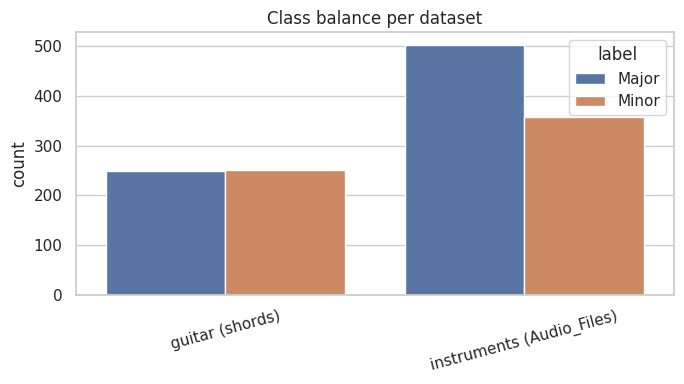

In [2]:
rows = []
for name, d in DATA_DIRS.items():
    for label_dir in sorted(d.iterdir()):
        if label_dir.is_dir():
            n = len([f for f in label_dir.iterdir() if f.suffix.lower() in config.AUDIO_EXTENSIONS])
            rows.append({'dataset': name, 'label': label_dir.name.capitalize(), 'count': n})
counts = pd.DataFrame(rows)
display(counts.pivot_table(index='dataset', columns='label', values='count', aggfunc='sum', margins=True))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(counts, x='dataset', y='count', hue='label', ax=ax)
ax.set_title('Class balance per dataset'); ax.set_xlabel(''); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()


## 2. Noisy-data checks (assignment step 4)

**Silence:** very quiet clips carry no chord and should be filtered. We measure
loudness (RMS) and flag clips below the silence threshold.

**Tuning:** instruments not tuned to the standard 440 Hz reference are shifted in
pitch. `estimate_tuning_deviation` reports the shift as a fraction of a semitone
(0 = in tune). Large deviations are worth knowing about.


Total clips: 1361 | flagged as silent: 0
Tuning deviation: mean=+0.050 semitone, |dev|>0.2 in 4 clips


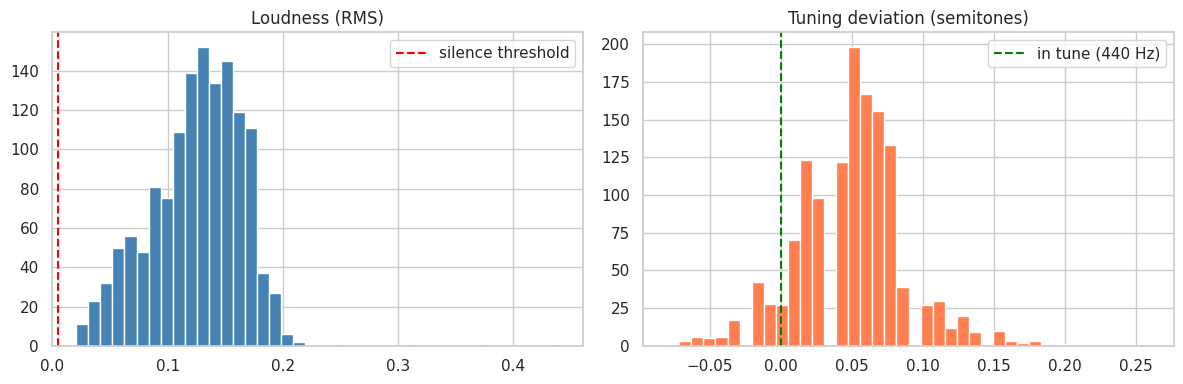

In [3]:
rms_vals, tuning_vals, labels = [], [], []
for d in DATA_DIRS.values():
    for path, label in dataset._iter_audio(d):
        y, sr = load_audio(str(path))
        silent, rms = is_silent(y)
        rms_vals.append(rms)
        tuning_vals.append(estimate_tuning_deviation(y, sr))
        labels.append(label)
rms_vals = np.array(rms_vals); tuning_vals = np.array(tuning_vals)

n_silent = int((rms_vals < config.RMS_SILENCE_THRESHOLD).sum())
print(f'Total clips: {len(rms_vals)} | flagged as silent: {n_silent}')
print(f'Tuning deviation: mean={tuning_vals.mean():+.3f} semitone, '
      f'|dev|>0.2 in {(np.abs(tuning_vals) > 0.2).sum()} clips')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(rms_vals, bins=40, color='steelblue')
axes[0].axvline(config.RMS_SILENCE_THRESHOLD, color='red', ls='--', label='silence threshold')
axes[0].set_title('Loudness (RMS)'); axes[0].legend()
axes[1].hist(tuning_vals, bins=40, color='coral')
axes[1].axvline(0, color='green', ls='--', label='in tune (440 Hz)')
axes[1].set_title('Tuning deviation (semitones)'); axes[1].legend()
plt.tight_layout(); plt.show()


## 3. What the features look like (assignment step 5)

Chroma measures how much energy sits on each of the 12 pitch classes (C, C#, ... B).
Averaging the chroma of every major clip and every minor clip shows *where* the two
differ — this is the "third" the whole task hinges on.


/home/bob/University/ML/Project/ChordClassifier/.venv/lib/python3.12/site-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=1024 is too large for input signal of length=690
  warnings.warn(


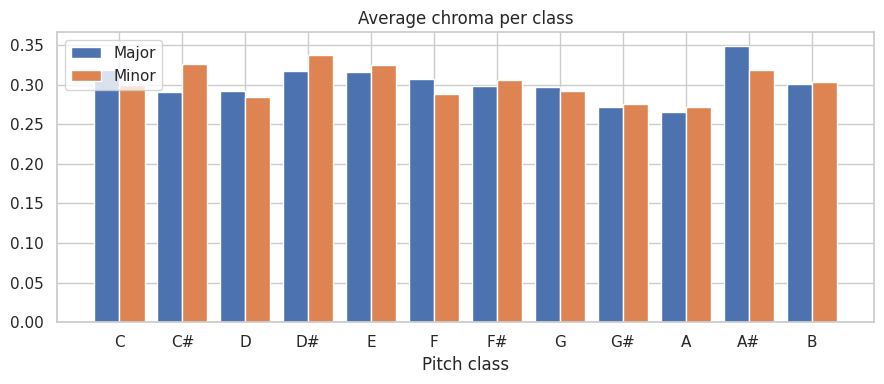

In [4]:
X, y = dataset.load_dataset(list(DATA_DIRS.values()), feature_type=config.FEATURE_CHROMA_VECTOR)
mean_chroma = X[:, :config.N_CHROMA]  # first 12 numbers = average chroma

fig, ax = plt.subplots(figsize=(9, 4))
width = 0.4; idx = np.arange(config.N_CHROMA)
for i, cls in enumerate(['Major', 'Minor']):
    ax.bar(idx + (i - 0.5) * width, mean_chroma[y == cls].mean(0), width, label=cls)
ax.set_xticks(idx); ax.set_xticklabels(config.NOTE_NAMES)
ax.set_title('Average chroma per class'); ax.set_xlabel('Pitch class'); ax.legend()
plt.tight_layout(); plt.show()


## 4. PCA cluster visualization (assignment step 6)

PCA squashes the 24-dimensional chroma vectors down to 2D so we can see whether
major and minor clips separate. Clear separation means the features are doing
their job before we even train a model.


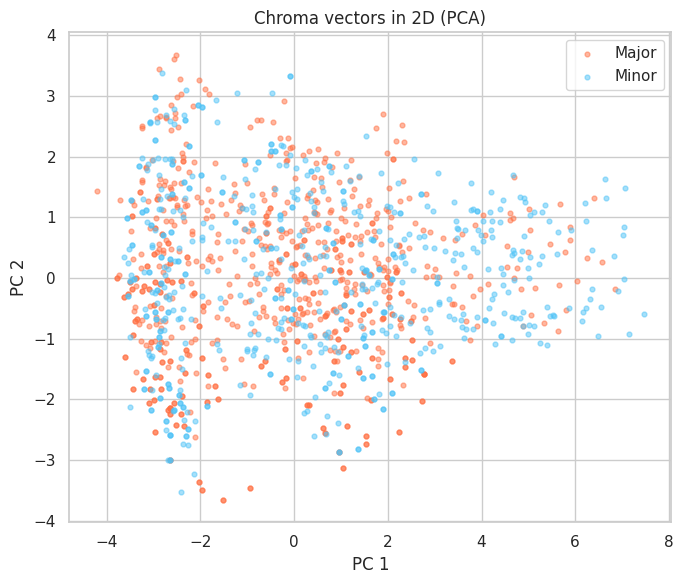

In [5]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Xs = StandardScaler().fit_transform(X)
pcs = PCA(n_components=2, random_state=42).fit_transform(Xs)

fig, ax = plt.subplots(figsize=(7, 6))
for cls, color in [('Major', '#ff7043'), ('Minor', '#4fc3f7')]:
    m = y == cls
    ax.scatter(pcs[m, 0], pcs[m, 1], s=12, alpha=0.5, label=cls, color=color)
ax.set_title('Chroma vectors in 2D (PCA)'); ax.set_xlabel('PC 1'); ax.set_ylabel('PC 2'); ax.legend()
plt.tight_layout(); plt.show()


## Takeaways

- The datasets are roughly balanced (a slight major-majority), so no heavy
  re-balancing is needed beyond the models' `class_weight`.
- Silence and tuning checks give us a cheap way to reject junk input in the app.
- The average-chroma plot shows the major/minor difference concentrated on a few
  pitch classes (the third), and PCA shows the two classes already partly separate
  — which is why even simple models do well once the features are right.
